In [177]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_aluguel = pd.read_csv("data.csv", low_memory=False)
display(df_aluguel)

,address,district,area,bedrooms,garage,type,rent,total
0,Rua Herval,Belenzinho,21,1,0,Studio e kitnet,2400,2939
1,Avenida São Miguel,Vila Marieta,15,1,1,Studio e kitnet,1030,1345
2,Rua Oscar Freire,Pinheiros,18,1,0,Apartamento,4000,4661
3,Rua Júlio Sayago,Vila Ré,56,2,2,Casa em condomínio,1750,1954
4,Rua Barata Ribeiro,Bela Vista,19,1,0,Studio e kitnet,4000,4654
...,...,...,...,...,...,...,...,...
11652,Avenida Adolfo Pinheiro,Santo Amaro,94,2,1,Apartamento,4100,5778
11653,Rua Professor Alexandre Correia,Jardim Vitória Régia,350,4,4,Apartamento,11250,17480
11654,Rua Abílio Borin,Jardim Caravelas,84,1,2,Apartamento,4500,5467
11655,Rua Forte William,Jardim Fonte do Morumbi,76,1,0,Apartamento,9000,10200


Podemos observar acima a tabela contendo todas as informações do arquivo principal do dataset de Preços de aluguéis em São Paulo: ***"data.csv"***.

No entanto, ela está repartida em **8 colunas(*columns*)**, e **11657 linhas(*rows*)**, cada uma dessas linhas e colunas estão contendo informações sobre o dataset, no código abaixo veremos o que cada linha e coluna representa:

In [178]:
display(list(df_aluguel.columns))


['address', 'district', 'area', 'bedrooms', 'garage', 'type', 'rent', 'total']

Ao inserirmos uma nova célula e digitarmos o código: "**display(list(df_aluguel.columns**))", a mensagem a ser imprimida será uma lista contendo todas as colunas presentes na tabela, sendo eles: **address(*Endereço*), district(*Bairro*),  area(*Área*), bedrooms(*Quartos*), garage(*Vagas na garagem*), type(*Tipo de imóvel*), rent(*Valor do aluguel*), total(*Valor total (aluguel + demais custos*))**.

Em relação as **linhas(*rows*)** estão divididas tendo cada as informações de cada coluna em específico: **'address', 'district', 'area', 'bedrooms', 'garage', 'type', 'rent', 'total'**, assim como mostrado no display. No entanto cada linha terá um valor diferente para cada coluna, como por exemplo:

In [179]:
display(df_aluguel.head(2))

,address,district,area,bedrooms,garage,type,rent,total
0,Rua Herval,Belenzinho,21,1,0,Studio e kitnet,2400,2939
1,Avenida São Miguel,Vila Marieta,15,1,1,Studio e kitnet,1030,1345


Nesse display acima podemos observar que em cada uma das linhas os valores de cada coluna são diferentes, na linha de índice 0, o "address" está como: **"Rua Herval"**, e na de índice 1, está como: **"Vila Marieta"**. Não só essas como também o **valor do aluguel(*rent*)** que na de índice 1 é = **2400,00** , e na de índice 2 é = **1030,00**

Agora verificaremos se há valores ausentes, algum registro repetido ou valores inconcistentes. Ao dar **"display(df_aluguel.info())"** podemos ter as **informações sobre o dataset.**

In [180]:
display(df_aluguel.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11657 entries, 0 to 11656
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   address   11657 non-null  object
 1   district  11657 non-null  object
 2   area      11657 non-null  int64 
 3   bedrooms  11657 non-null  int64 
 4   garage    11657 non-null  int64 
 5   type      11657 non-null  object
 6   rent      11657 non-null  int64 
 7   total     11657 non-null  int64 
dtypes: int64(5), object(3)
memory usage: 728.7+ KB


None

Em relação aos valores ausentes podemos notar que todas as colunas estão totalmente preenchidas ao se  olhar para coluna **"Non-Null Count"** que seriam a quantidade de valores não nulos (***valores preenchidos e não ausentes***) e em todas as colunas constam como **11657 non-null**. No entanto se ouvesse algum valor vazio, poderiamos simplesmente preenchê-los usando o código: **"df_aluguel["coluna_vazia"] = df_aluguel["coluna_vazia"].fillna("Vazio")".**


Em relação as duplicatas, podemos analisar todas as colunas utilizando: **"display(df_aluguel.duplicated(subset=[["coluna1", "coluna2", "etc"]]))"** esse código faz com que haja uma ***verificação em série boolena*** em que se retornar ***"True"*** caso ela seja uma duplicata de outra anterior,considerando todas as linhas, já se retornar ***"False"*** é o sentido contrário, indicando que aquela linha não é uma duplicata.



In [181]:
display(df_aluguel.duplicated(subset=["address"]))

,0
0,False
1,False
2,False
3,False
4,False
...,...
11652,True
11653,True
11654,False
11655,True


Aqui vemos que algumas linhas da coluna "address" estão duplicatas, elas retornam o valor **"True"**. Para solucionar isso basta apenas digitar esse comando:

In [182]:
df_aluguel = df_aluguel.drop_duplicates(subset=["address"])
display(df_aluguel.duplicated(subset=["address"]))

,0
0,False
1,False
2,False
3,False
4,False
...,...
11639,False
11642,False
11643,False
11651,False


Após o comando, vemos que as não consta mais nenhuma linha duplicada.

Agora verificaremos se há algum valor inconcistente. Faremos 5 etapas de verificações:



1.   Verificar se a coluna "area" em alguma linha é igual ou menor que zero.
2.   Verificar se há valores negativos nas colunas numéricas.
3.   Verificar se o valor total é menor que o aluguel(rent).
4.   Verificar imóveis com zero quartos, bedrooms = 0.
5.   E por último, identificar valores atípicos no aluguel, como: 15000 ou 20000.



In [183]:
df_aluguel["area"] <= 0

,area
0,False
1,False
2,False
3,False
4,False
...,...
11639,False
11642,False
11643,False
11651,False


Podemos ver que ao digitarmos **"df_aluguel["area"] <= 0"** ele faz uma busca em série booleana em valores cuja a coluna **"area"** seja menor ou igual a 0. Após a busca vemos que **não há nenhum valor inconcistente**. Mas para que não haja realmente nenhum valor igual a 0, vamos atualizar a coluna e colocar somente valores acima 0.

In [184]:
df_aluguel = df_aluguel[df_aluguel['area'] > 0]

Agora foram exluídas todas as colunas de 'area' iguais a 0.

In [185]:
df_aluguel[["area", "bedrooms", "garage", "rent", "total"]] <= 0

,area,bedrooms,garage,rent,total
0,False,False,True,False,False
1,False,False,False,False,False
2,False,False,True,False,False
3,False,False,False,False,False
4,False,False,True,False,False
...,...,...,...,...,...
11639,False,False,False,False,False
11642,False,False,True,False,False
11643,False,False,False,False,False
11651,False,False,False,False,False


Ao verificarmos todos os valores numéricos, vemos que algumas colunas de **"garage"** retornaram **"True"**, então há locais que não tem garagem em seu estabelecimento, mas isso é comum pois nem todo lugar háverá garagem. Então não hpa valores inconcistentes.

In [186]:
df_aluguel["total"] < df_aluguel["rent"]

,0
0,False
1,False
2,False
3,False
4,False
...,...
11639,False
11642,False
11643,False
11651,False


Verificamos se há algum valor da coluna **"total"** que é menor que a coluna de valor de aluguel(rent) e pelo visto não, então valores concistentes até então.

In [187]:
df_aluguel["bedrooms"] <= 0

,bedrooms
0,False
1,False
2,False
3,False
4,False
...,...
11639,False
11642,False
11643,False
11651,False


Verificação de valores da coluna de **Quartos("bedrooms")** e os valores impressos foram "False", sem valores inconcistentes.

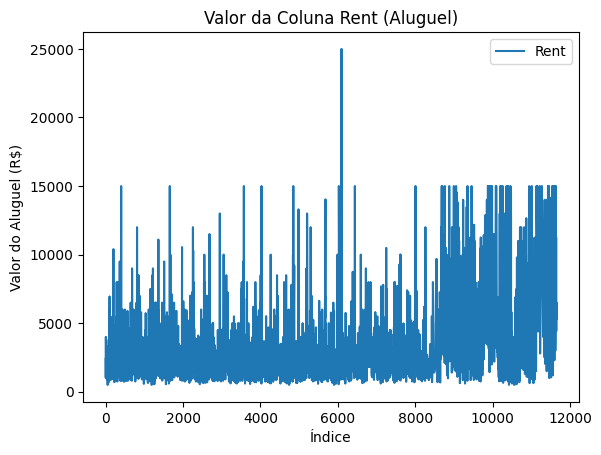

In [188]:
plt.plot(df_aluguel["rent"])
plt.xlabel('Índice')
plt.ylabel('Valor do Aluguel (R$)')
plt.title('Valor da Coluna Rent (Aluguel)' )
plt.legend(['Rent'])
plt.show()

Utilizando um gráfico, podemos visualizar que há uma linha que alcança a escala de **R$25.000** de acrodo com a representação do gráfico, então ha um valor atípico entre a coluna **"rent"**, e como resolver isso? Simples, aplicamos um comando em que exclua essa coluna, sendo ele:

In [189]:
df_aluguel = df_aluguel[df_aluguel['rent'] <= 15000]

O código acima faz uma atualizição na coluna 'rent' mantendo somente valores abaixo de R$15.000 ou igual.

E com isso fizemos os tratamento de todos os dados, organizando e excluindo valores indesejados, corrigindo colunas vazias e verificando valores atípicos e inconcistentes. Deixando nossa tabela assim no momento:

In [190]:
display(df_aluguel.info())
display(df_aluguel.describe())

<class 'pandas.core.frame.DataFrame'>
Index: 5346 entries, 0 to 11654
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   address   5346 non-null   object
 1   district  5346 non-null   object
 2   area      5346 non-null   int64 
 3   bedrooms  5346 non-null   int64 
 4   garage    5346 non-null   int64 
 5   type      5346 non-null   object
 6   rent      5346 non-null   int64 
 7   total     5346 non-null   int64 
dtypes: int64(5), object(3)
memory usage: 375.9+ KB


None

,area,bedrooms,garage,rent,total
count,5346.000000,5346.000000,5346.000000,5346.000000,5346.000000
mean,91.269547,2.057239,1.155817,3024.194725,3682.816498
std,79.044086,0.937972,1.203457,2502.663865,3047.573221
min,1.000000,0.000000,0.000000,500.000000,509.000000
25%,45.000000,1.000000,0.000000,1480.250000,1780.250000
50%,64.000000,2.000000,1.000000,2250.000000,2810.000000
75%,101.000000,3.000000,2.000000,3500.000000,4345.750000
max,580.000000,6.000000,6.000000,15000.000000,25510.000000


Agora iremos calcular a média e a mediana dos aluguéis, utlizaremos o comando **" media = df_aluguel["rent"}.mean()"**  e o **" mediana = df_aluguel["rent"].median()"** :

In [191]:
media = df_aluguel["rent"].mean()
mediana = df_aluguel["rent"].median()
print(f"A média dos aluguéis é: {media}")
print(f"A mediana dos aluguéis é: {mediana}")

A média dos aluguéis é: 3024.194725028058
A mediana dos aluguéis é: 2250.0


Calculamos a média e a mediana de acordo com as colunas do "rent" e os valores foram: **Média = 3028.33... e Mediana = 2250.0**.  Os valores foram diferentes ,porquê? simples, a média vai **somar todos os valores** da coluna "rent" e **dividir pela quantidade** dando o resultado, já a mediana vai ser o **valor central da coluna** "rent" sendo ele = **2250.0!**

A média também ficou maior por conta de haver valores muito elevados de aluguéis. Há aluguéis acima de **R$10.000.**

Seguindo, vamos identificar as localidades com maiores e menores preços médios, então teriamos que fazer um agrupamento utilizando as colunas: **"address", "rent" e "district"**.

In [192]:
localidades = df_aluguel.groupby('district')['rent'].agg(
    preco_medio='mean',
    quantidade='count'
)

localidades = localidades[localidades['quantidade'] >= 30]

maiores = localidades.sort_values(
    'preco_medio', ascending=False
).head(20)

menores = localidades.sort_values(
    'preco_medio', ascending=True
).head(20)

print("Maiores preços médios:")
display(maiores.round(2))

print("\nMenores preços médios:")
display(menores.round(2))


Maiores preços médios:


,preco_medio,quantidade
district,,
Campo Belo,4964.08,36
Pinheiros,4784.14,42
Vila Suzana,4698.80,30
Santo Amaro,4695.81,63
Vila Regente Feijó,4160.09,35
Mooca,4050.40,52
Vila Mariana,3819.80,83
Indianópolis,3703.67,30
Perdizes,3633.44,34



Menores preços médios:


,preco_medio,quantidade
district,,
Liberdade,1791.30,30
Brás,2089.60,30
Cambuci,2174.19,36
Vila Formosa,2176.59,39
Centro,2255.57,49
Bela Vista,2732.04,72
Vila Andrade,2909.71,41
Ipiranga,2930.28,32
Santana,2996.08,51


Nas tabelas acima mostram as localidades com as 20 maiores médias de aluguel, e as 20 menores. Para isso, tivemos que agrupar as colunas **"district"** e **"address"**, e seleciona a coluna ***"rent"*** com as informações dos valores de aluguel, depois criamos a variável: ***"preco_medio = 'mean'"*** que vai fazer o **cálculo das médias dos valores** e a variável: ***"quantidade = 'count'"*** que vai contar a quantidade valores que tem na coluna. Após isso criamos: **"localidades = localidades[localidades['quantidade'] >= 30] "** que remove locais com ***30 ou menos quantidade de imóveis.*** Depois geramos o comando: "maiores = localidades.sort_values(
    'preco_medio', ascending=False
).head(10)" **negrito** que simplesmente organiza os bairros pelo preoço médio e são gerados de forma **descrescente(ascending=False)**, gerando a lista das localidades com maiores preços médios, e para fazer a lista de menores, basta colocar a ordem para **crescente(ascending=True)** e pronto, lista dos locais com menores preços médios feita.



Utilizamos o **.head(10)** para imprimir somente 10 linhas, e o **.round(2)** arrendonda os valores para somente duas casas decimais.

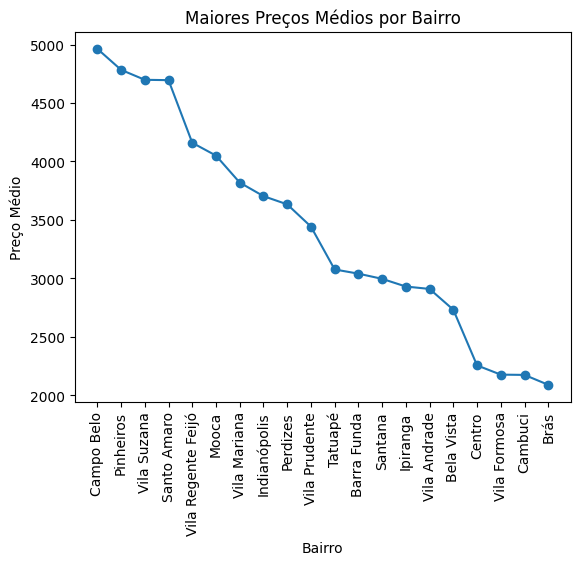

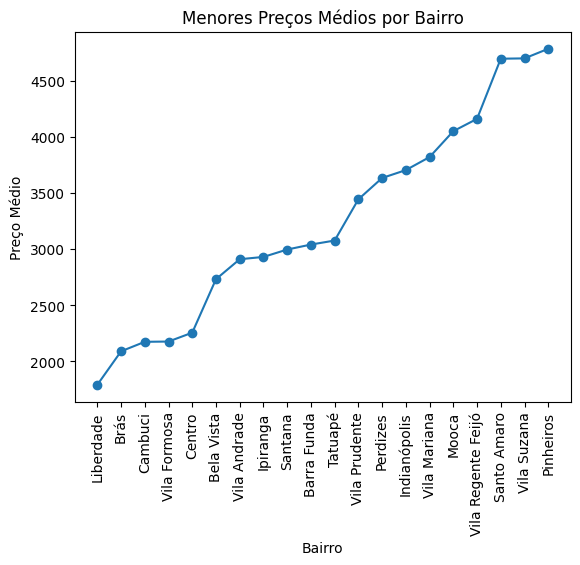

In [193]:
plt.plot(maiores.index, maiores['preco_medio'], marker='o')
plt.xlabel('Bairro')
plt.ylabel('Preço Médio')
plt.title('Maiores Preços Médios por Bairro')
plt.xticks(rotation=90)
plt.show()

plt.plot(menores.index, menores['preco_medio'], marker='o')
plt.xlabel('Bairro')
plt.ylabel('Preço Médio')
plt.title('Menores Preços Médios por Bairro')
plt.xticks(rotation=90)
plt.show()

Vamos utilizar gráficos que permite uma melhor visualização de informações. Acima vemos dois gráficos:

**Gráfico 1** -> Mostra os **20 maiores preços médios**, Cada ponto representa um **bairro**, permitindo comparar os valores e observar as diferenças entre eles.

**Gráfico 2** -> Mostra os 20 menores preços médios, trazendo uma visibilidade melhor para locais com maior acessibilidade.

Em ambos os gráficos, o eixo horizontal **plt.xticks(rotation=90)** representa os bairros e o eixo vertical representa o preço médio do aluguel. A rotação dos nomes em 90° facilita a leitura das localidades.

In [194]:
correlacao_area = df_aluguel['rent'].corr(df_aluguel['area'])

correlacao_quartos = df_aluguel['rent'].corr(df_aluguel['bedrooms'])

print(f"Correlação entre aluguel e área: {correlacao_area:.2f}")
print(f"Correlação entre aluguel e quartos: {correlacao_quartos:.2f}")

Correlação entre aluguel e área: 0.71
Correlação entre aluguel e quartos: 0.58


No código acima fizemos uma correlação entre colunas, sendo a principal: **"rent"**, e correlacionando ela com as colunas: **"area" e "bedrooms"**.

A correlação entre o **"rent" e a "area"** indica: Se imóveis com **maior área** tendem a ter aluguéis mais altos ou mais baixos.

Já a correlação entre **"rent" e "bedrooms"** indica: Se houver uma maior **quantidade de quartos** no imóvel, tende a ter um aluguel ***mais alto ou mais baixo.***

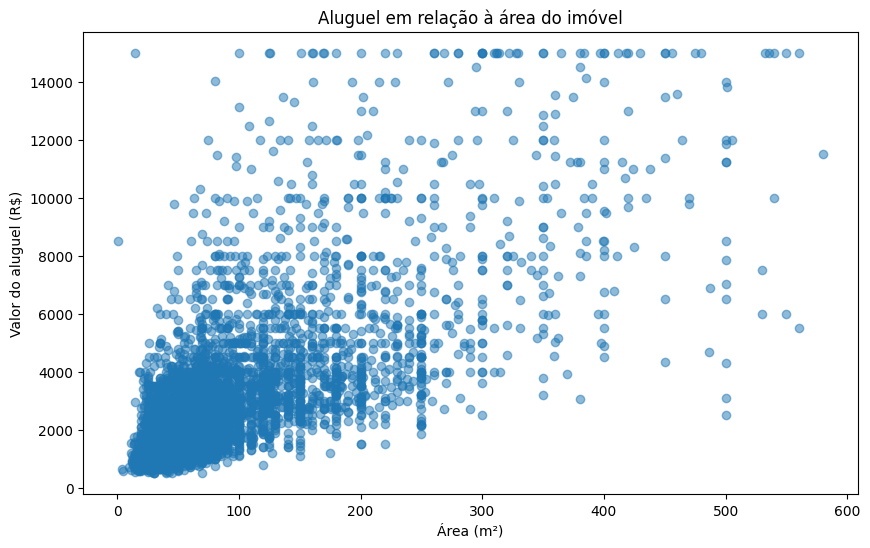

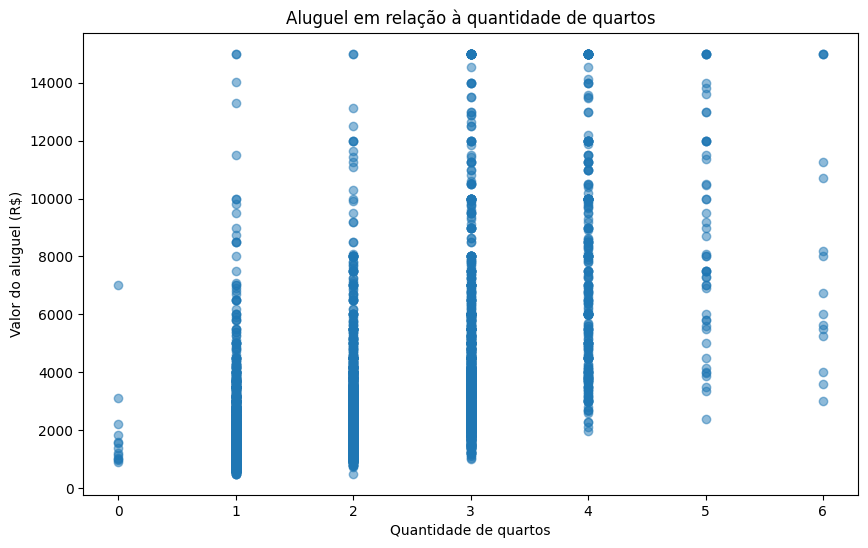

In [195]:
plt.figure(figsize=(10, 6))
plt.scatter(df_aluguel['area'], df_aluguel['rent'], alpha=0.5)
plt.xlabel('Área (m²)')
plt.ylabel('Valor do aluguel (R$)')
plt.title('Aluguel em relação à área do imóvel')
plt.show()


plt.figure(figsize=(10, 6))
plt.scatter(df_aluguel['bedrooms'], df_aluguel['rent'], alpha=0.5)
plt.xlabel('Quantidade de quartos')
plt.ylabel('Valor do aluguel (R$)')
plt.title('Aluguel em relação à quantidade de quartos')
plt.show()

Criamos um gráfico para facilitar a visualização das correlações:

**Gráfico 1** -> Está representando a relação entre a** área dos imóveis**, em metros quadrados, e o **valor do aluguel**. Cada ponto representa um imóvel. O gráfico permite observar se **imóveis com áreas maiores tendem a apresentar aluguéis mais elevados.**

**Gráfico 2** -> Representa a relação entre o **número de quartos** e o **preço do aluguel**. Cada ponto representa um imóvel, permitindo verificar se **imóveis com mais quartos tendem a ter aluguéis mais caros.**

Com isso podemos tirar 5 conclusões com todo esse progresso feito até então:

1. **A diferença entre a Média e a Mediana:** O preço médio dos aluguéis foi de aproximadamente 3.028,34, enquanto a mediana foi de 2.250,00. Isso indica que os aluguéis mais elevados aumentam a média.

2. **Relação entre os alugueis com a área dos imóveis:** A correlação de aluguel com a área foi de 0,70, indicando uma relação positiva relativamente forte. Em geral, imóveis com áreas maiores tendem a apresentar aluguéis mais elevados.

3. **Relação entre os aluguéis com a quantidade de quartos dos imóveis:** A correlação de quartos com aluguel foi de 0,57, indicando uma relação positiva moderada. Imóveis com mais quartos tendem a apresentar aluguéis maiores, embora essa relação seja menos intensa do que a observada com a área.

4. **Bairros com maiores preços médios:** Entre as localidades analisadas com pelo menos 30 registros, Campo Belo apresentou o maior preço médio, de aproximadamente R$ 4.964,08 por mês.

5. **Bairros com menores preõs médios:** Entre as localidades que atenderam ao mesmo critério, Liberdade apresentou o menor preço médio, de aproximadamente R$ 1.791,30 por mês. A diferença em relação a Campo Belo evidencia variações relevantes entre os bairros analisados.



Algumas limitações das analises com base nas informações fornecidas:

1. **Ausência de informações:** O conjunto de dados não apresenta todos os fatores que podem influenciar o aluguel, como: ***estado de conservação do imóvel, mobiliário, condomínio e proximidade de serviços.***

2. **Concentração dos anúncios:** A quantidade de anúncios varia entre os bairros analisados. Por isso, os resultados de bairros com menos registros podem ser menos representativos.

3. **Preços anunciados:** Os valores representam os preços informados nos anúncios, que podem ser **diferentes dos valores** efetivamente negociados entre proprietários e inquilinos.

4. **Exclusão de registros:** A análise removeu endereços repetidos e anúncios com aluguel superior a R$ 15.000. Essa decisão pode ter excluído imóveis **válidos e influenciado as médias calculadas.**

5. **Dados inconsistentes:** Foram identificados valores de área iguais a zero e registros com zero quartos, que precisam ser verificados para evitar distorções nos resultados.

6. **Correlação não significa causalidade:** Embora a área tenha apresentado correlação positiva com o aluguel, isso não significa que ela seja a única responsável pelo aumento dos preços.

Com tudo, os resultados ajudam a compreender os padrões dos aluguéis anunciados em São Paulo, mas devem ser interpretados considerando as limitações e a qualidade dos dados utilizados.

Pergunta orientadora: quais características parecem acompanhar os maiores e os menores preços de aluguel e o que os dados não permitem concluir?


Em resposta a pregunta dados informados pela análise demonstram que a correlação entre a área e os valores de aluguel foram de 0,70 e a correlação entre quartos e aluguéis foram de 0,57 o que indica que um imóvel com uma área bastante extensa e com posse de uma grande quantidade de quartos, faça com que o valor daquele imóvel aumente. Entretanto, há a falta de informações que contam na hora de precificar o imóvel como sua **conservação, condomínio, proximidade de serviços, localidade, infraestrutura**, que não foram informados e com isso não podemos afirma que somente a área e a quantidade de banheiros interferem no aumento ou da diminuição de preço da propriedade.